
# Honeybee nest: masked-convolutional autoregressive model

End-to-end reproduction of the paper's nest-content **prediction** pipeline
with the `combinator` package: load and relabel the 4D colony grids, spatially
align and crop them, (optionally) train the masked-convolutional
`SpatialClassifier`, assemble the 18-hive evaluation set (6 control + 6
physically shuffled + 6 simulated-shuffled colonies), run the **eight committed
checkpoints** (`models/`), and regenerate the paper figures (in-cell below).

The eight trained checkpoints in `models/` are used **as-is**: they are loaded
directly (via `models/`) and never re-trained by this notebook. A short
2-epoch training run is performed below only to smoke-test the package
training API; every figure, table and number below comes from the committed
checkpoints.

Run from the repository root (all relative paths assume that); a CUDA GPU
speeds up evaluation. Pick a GPU with `CUDA_VISIBLE_DEVICES` if you want a
specific one. Example:

    python -m jupyter notebook autoregressive_model.ipynb


In [1]:

import os

import torch

import combinator
from combinator import (
    DEFAULT_NAMES,
    V2_MODELS,
    build_eval_hives,
    evaluate_all_v2,
    load_grids,
    map_all_labels,
    process_grids,
    train_spatial_classifier,
)

device = "cuda:0" if torch.cuda.is_available() else "cpu"
print(f"combinator {combinator.__version__} on {device} "
      f"({torch.cuda.get_device_name(0) if device != 'cpu' else 'cpu'})")


combinator 0.1.0 on cuda:0 (NVIDIA RTX A5000)



## 1. Load, relabel, align and crop the colony grids

`data/AllColoniesCombinedDS48v2.zip` holds the 12 colonies as 4D weekly grids
(weeks x 20 comb-sides x height x width) in the paper's detailed label space.
`map_all_labels` remaps the 21 detailed content classes to the six simplified
classes the model predicts; `process_grids` spatially aligns colonies to each
other, crops to the shared mean-wood bounding box (52 x 104), and cleans
invalid voxels.


In [2]:

grids = load_grids("data/AllColoniesCombinedDS48v2.zip")
print(f"loaded {len(grids)} colonies; raw shapes: {[g.shape for g in grids]}")

grids = map_all_labels(grids)          # 21 detailed classes -> 6 simple classes
grids = process_grids(grids)           # align + wood-bbox crop (52 x 104) + clean

print(f"aligned/cropped: {[g.shape for g in grids]}")
print(f"class range: {max(int(g.max()) for g in grids) + 1} classes")


loaded 12 colonies; raw shapes: [(20, 20, 77, 116), (20, 20, 77, 116), (20, 20, 77, 116), (20, 20, 77, 116), (20, 20, 77, 116), (17, 20, 77, 116), (20, 20, 77, 116), (20, 20, 77, 116), (14, 20, 77, 116), (20, 20, 77, 116), (20, 20, 77, 116), (17, 20, 77, 116)]
Zero variance detected in grid 1, frame indices (0, 2)
Zero variance detected in grid 1, frame indices (0, 2)
Zero variance detected in grid 4, frame indices (0, 9)
Zero variance detected in grid 4, frame indices (0, 9)
Zero variance detected in grid 9, frame indices (0, 3)
Zero variance detected in grid 9, frame indices (0, 3)
aligned/cropped: [(20, 20, 52, 104), (20, 20, 52, 104), (20, 20, 52, 104), (20, 20, 52, 104), (20, 20, 52, 104), (17, 20, 52, 104), (20, 20, 52, 104), (20, 20, 52, 104), (14, 20, 52, 104), (20, 20, 52, 104), (20, 20, 52, 104), (17, 20, 52, 104)]
class range: 6 classes



## 2. Training (package API, short demo)

`train_spatial_classifier` trains one `SpatialClassifier` with the paper's
recipe: AdamW (lr 1e-3, wd 1e-5, betas (0.9, 0.95)) with the embedding and
positional-bias groups at 10x the base lr, 5-epoch linear warmup + cosine
annealing, batch size 8, and a class-weighted cross-entropy loss (inverse
training-set class frequencies), plus the paper's training-only width-flip
augmentation (`flip_aug=True`; prediction never augments).

The cell below runs a **2-epoch smoke test** on two colonies — it only
demonstrates the call signature and completes in seconds. The full recipe
that produced the committed checkpoints (`train_all_v2`: the six unshuffled
control colonies, 200 epochs, all eight configurations, seed 42) is shown
after it; it is guarded by a flag and is **not** executed here — the
checkpoints are taken from `models/` as-is for everything below.
See `models/MANIFEST.md` for the exact provenance.


In [3]:

# Demo only: 2 epochs on the first two colonies, showing the training API.
# The committed checkpoints in models/ were trained with this same routine
# at the full schedule and are used as-is everywhere below.
demo_model = train_spatial_classifier(
    grids[:2],
    seed=42,
    max_epochs=2,
    batch_size=8,
    device=device,
    enable_progress_bar=False,
)
n_params = sum(p.numel() for p in demo_model.parameters())
print(f"demonstration model: {type(demo_model).__name__}, {n_params:,} parameters")


demonstration model: SpatialClassifier, 476,032 parameters


/home/jake/projects/honeybee-nest/fork/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
/home/jake/projects/honeybee-nest/fork/.venv/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/jake/projects/honeybee-nest/fork/.venv/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.



### Full training (reproduces the committed checkpoints — many GPU-hours, not run here)


In [4]:

# The complete training reproduction, in package terms: one model per
# committed configuration, on the six unshuffled control colonies, full
# paper schedule + width-flip augmentation (see combinator.train.train_all_v2).
# Flip the flag to True to retrain all eight checkpoints into models/.
REPRODUCE_FULL_TRAINING = False

if REPRODUCE_FULL_TRAINING:
    combinator.train_all_v2(grids[:6], models_dir="models", seed=42,
                            device=device)


## 3. Prediction: the committed checkpoints on the 18-hive evaluation set

Figures can be produced either by re-running inference on the GPU, or
straight from the committed `results/` outputs (`USE_CACHED_RESULTS`)
with no GPU at all.

In [5]:

all_hives = build_eval_hives(grids, num_control=6, seed=42)
print(f"evaluation corpus: {len(all_hives)} hives "
      f"(0-5 control, 6-11 physically shuffled, 12-17 simulated)")

# Load each committed checkpoint by its registry entry and run inference.
results = evaluate_all_v2(all_hives, "models", device)
model_keys = list(results)
print(f"evaluated {len(model_keys)} checkpoints: {model_keys}")


evaluation corpus: 18 hives (0-5 control, 6-11 physically shuffled, 12-17 simulated)
evaluating spatial_classifier_v2_k1_dFalse_hFalse_wFalse_posFalse_ctxFalse_int0.pth ...
evaluating spatial_classifier_v2_k3_dFalse_hFalse_wTrue_posTrue_ctxTrue_int1.pth ...
evaluating spatial_classifier_v2_k3_dFalse_hTrue_wFalse_posTrue_ctxTrue_int1.pth ...
evaluating spatial_classifier_v2_k3_dTrue_hFalse_wFalse_posTrue_ctxTrue_int1.pth ...
evaluating spatial_classifier_v2_k3_dTrue_hFalse_wTrue_posTrue_ctxTrue_int1.pth ...
evaluating spatial_classifier_v2_k3_dTrue_hTrue_wFalse_posTrue_ctxTrue_int1.pth ...
evaluating spatial_classifier_v2_k3_dFalse_hTrue_wTrue_posTrue_ctxTrue_int1.pth ...
evaluating spatial_classifier_v2_k3_dTrue_hTrue_wTrue_posTrue_ctxTrue_int1.pth ...
evaluated 8 checkpoints: [(1, False, False, False, False, False, 0), (3, False, False, True, True, True, 1), (3, False, True, False, True, True, 1), (3, True, False, False, True, True, 1), (3, True, False, True, True, True, 1), (3, True,


## 4. Figures

All figure code lives in `combinator.plotting`; each likelihood/legend cell
below calls the package, rewrites its committed artifact under `figures/`, and
displays it in-cell (regenerated from the same checkpoints with seeded
bootstrap randomness — content-identical to the committed files, PDF
timestamps aside). The 3D voxel view is display-only: the committed
`figures/3d_predictions_likelihood.png` corresponds to the default hive/week
of `python -m combinator.make_figures`, while the view shown here matches the
authors' notebook (hive 1, week 8).


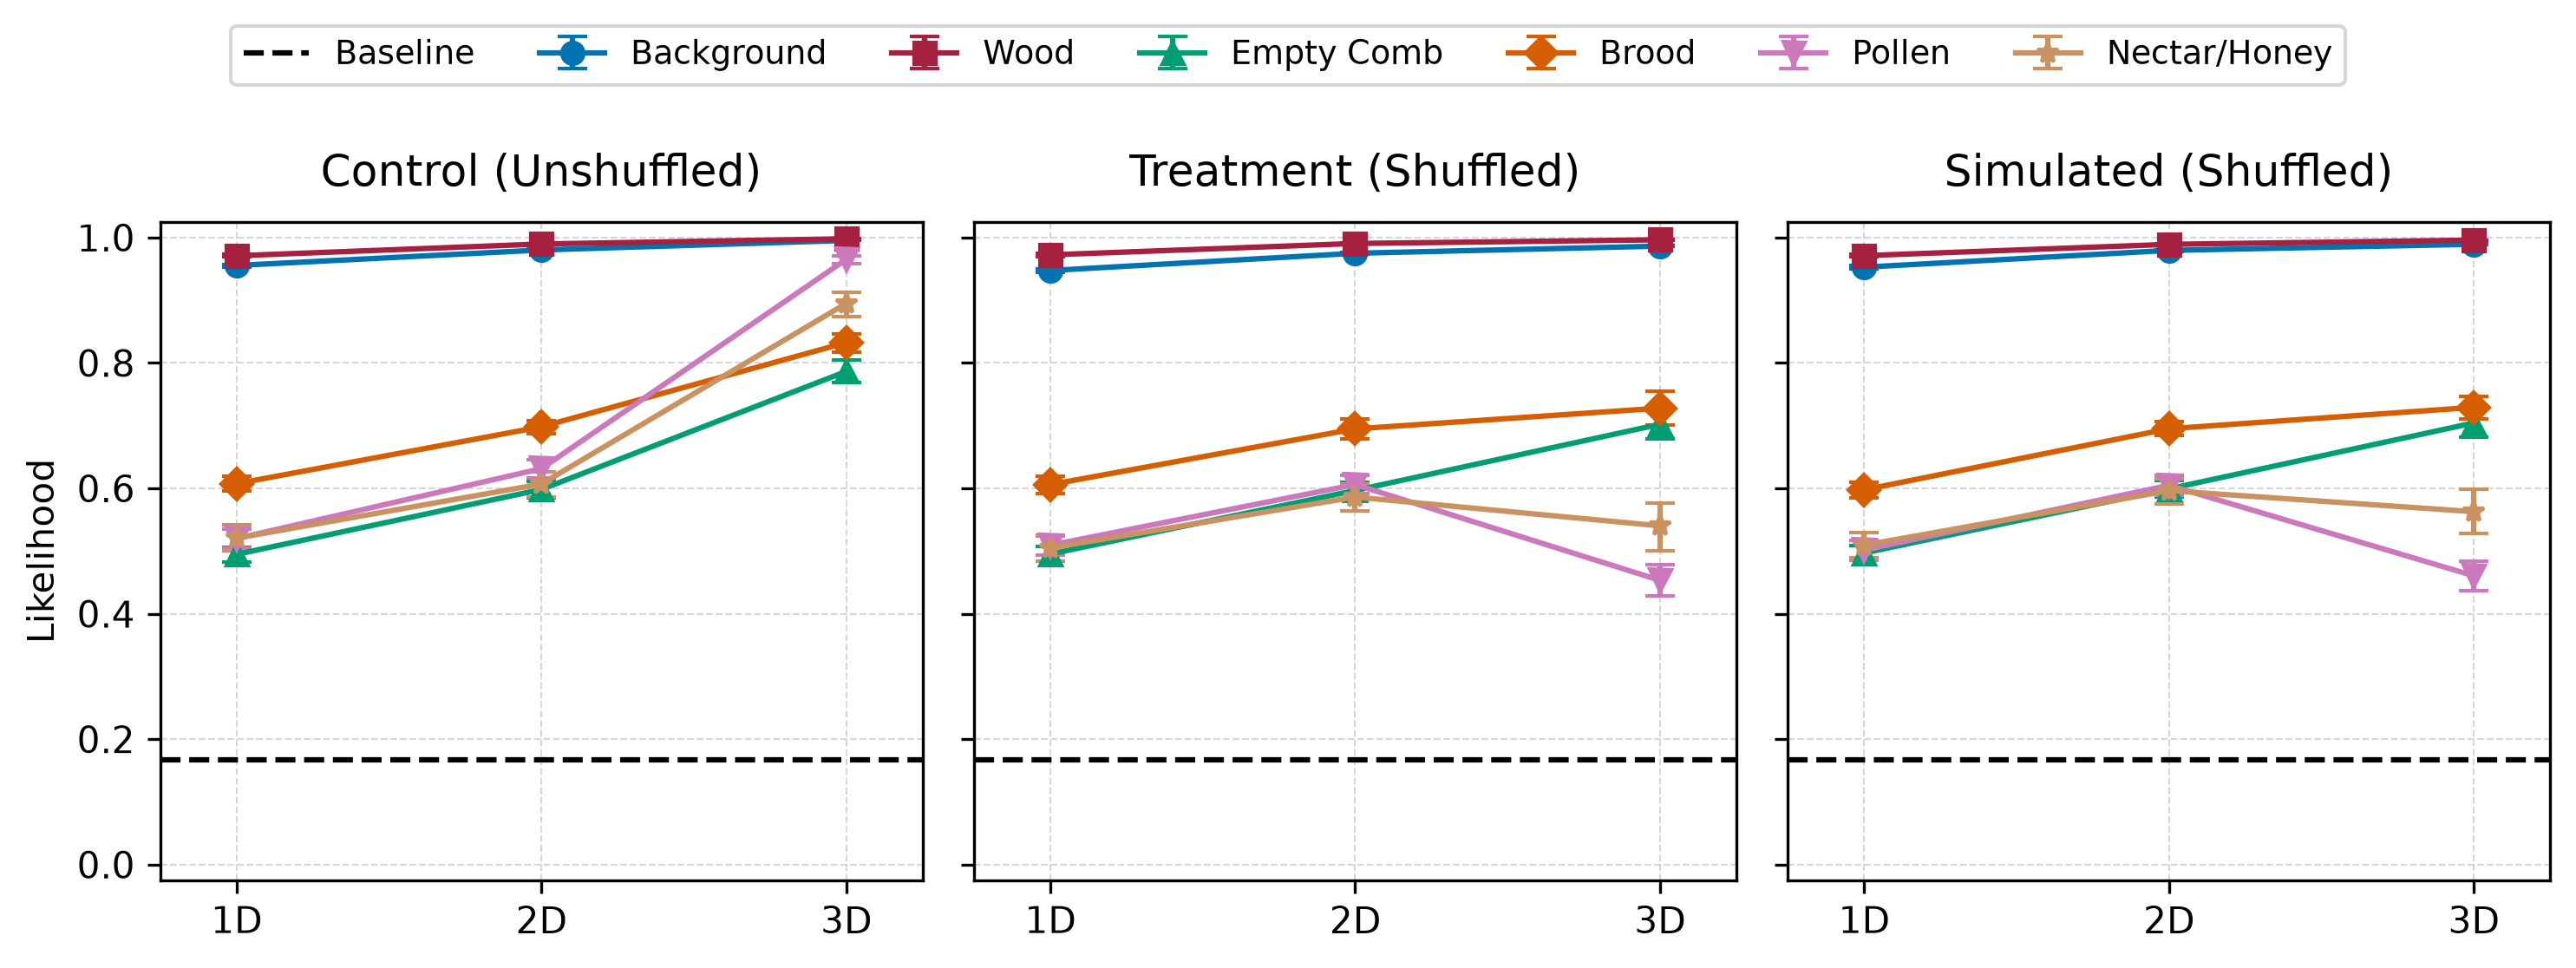

In [6]:

import matplotlib.pyplot as plt

# Figure 6: per-class mean likelihood, 1D/2D/3D-averaged, with
# hierarchical-bootstrap CIs and the k=1 (no spatial structure) baseline.
fig, axes = combinator.plot_control_physical_simulated(
    results, model_keys, num_classes=6, class_names=DEFAULT_NAMES)
fig.savefig("figures/control_physical_simulated_likelihood.pdf",
            bbox_inches="tight")
plt.show()


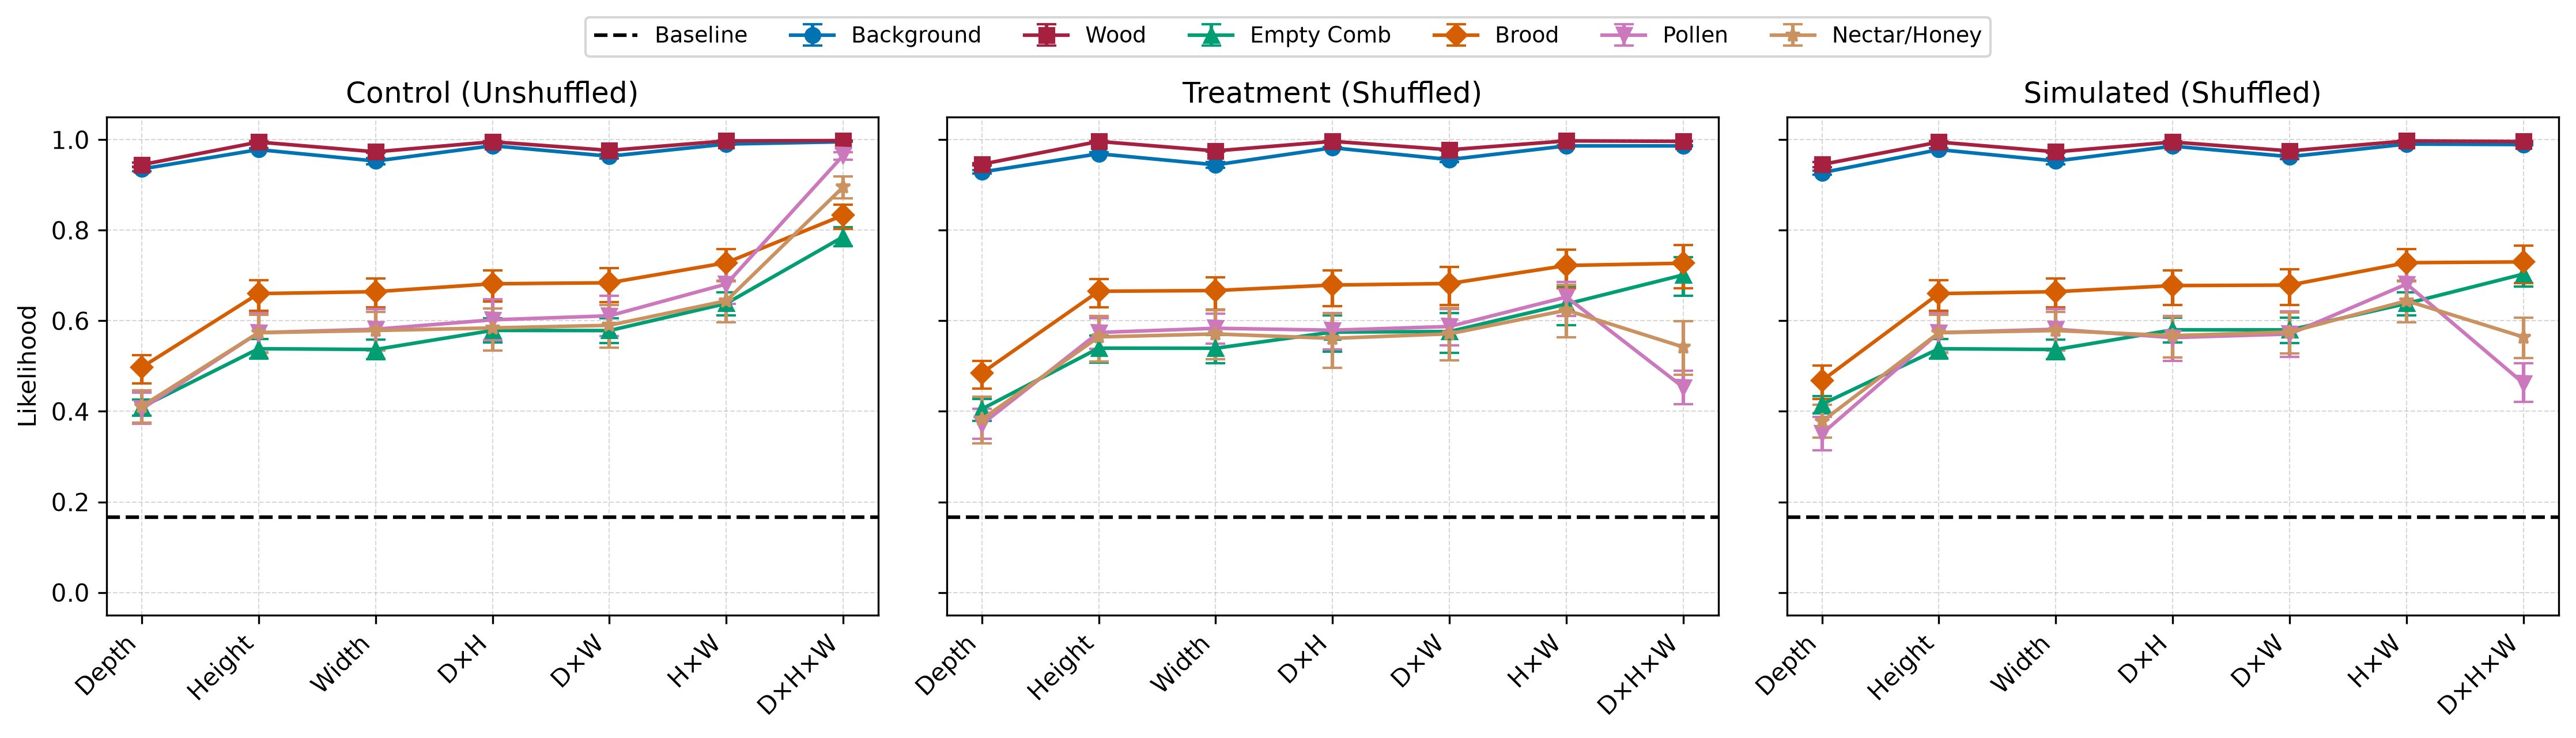

In [7]:

# Supplemental figure (Fig. S11): the seven individual 1D/2D/3D receptive-field
# configurations, per treatment group, against the pure-chance 1/6 baseline.
fig, axes = combinator.plot_control_physical_simulated_full(
    results, model_keys, num_classes=6, class_names=DEFAULT_NAMES)
fig.savefig("figures/supplement_config_likelihood.pdf", bbox_inches="tight")
plt.show()


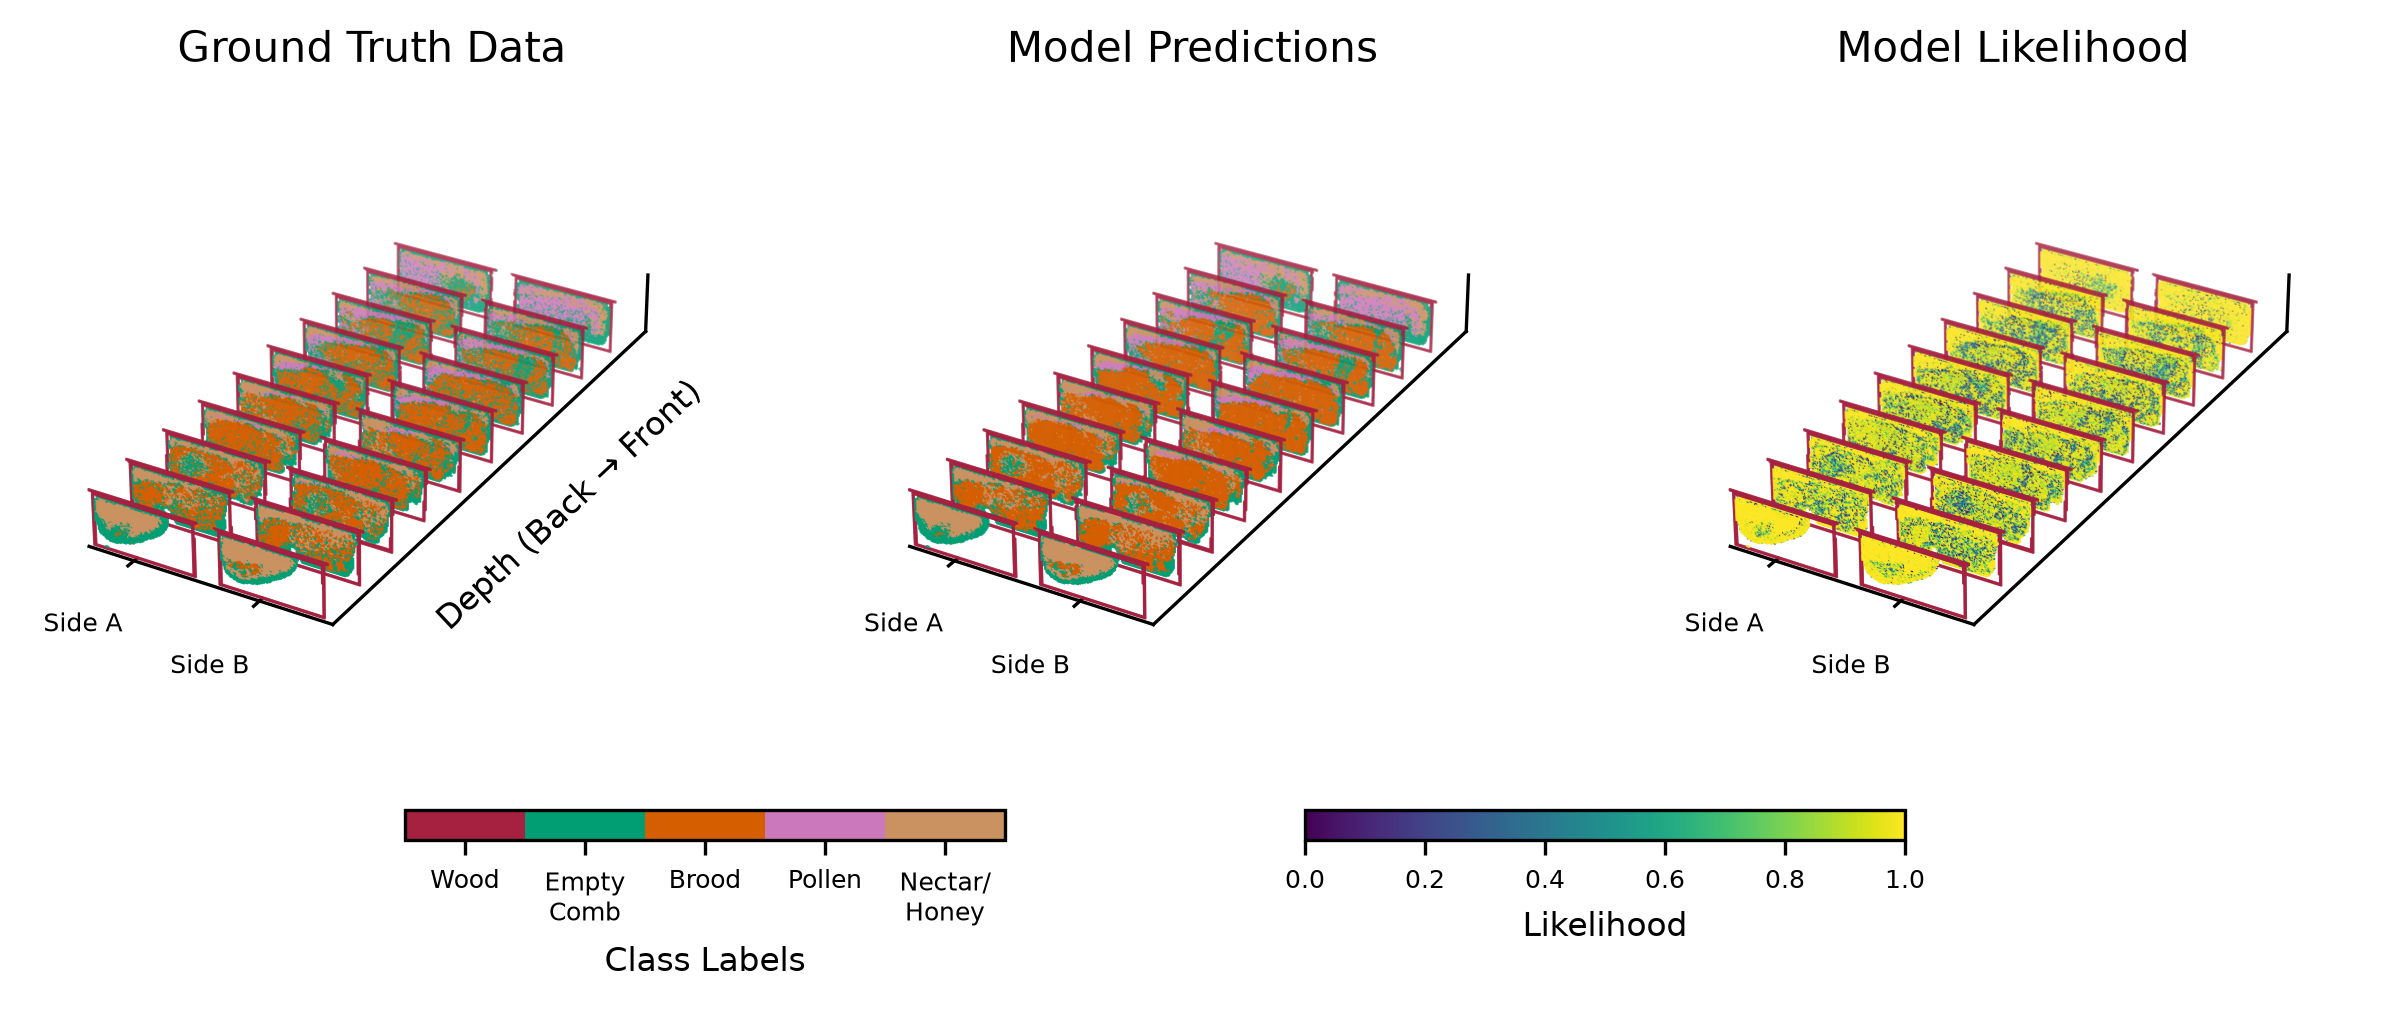

In [8]:

# Figure 6B: 3D voxel view (ground truth / predictions / likelihood) for one
# hive-week, rendered with the full 3D (depth x height x width) model.
d3d = next(k for k in model_keys if k[0] == 3 and k[1:4] == (True, True, True))
fig = combinator.plot_model_scatter3d_simplified(
    results, model_keys, model_idx=model_keys.index(d3d),
    hive_idx=1, week=8, show=True)
plt.show()


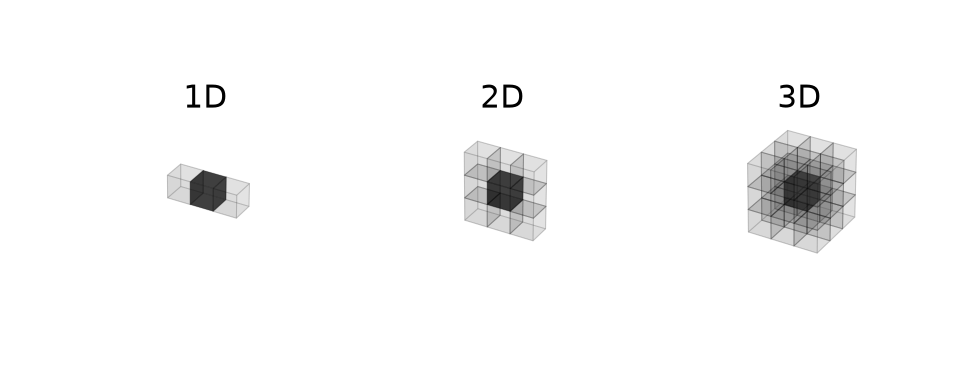

In [9]:

# Kernel legend: the masked 1D, 2D and 3D receptive fields.
fig = combinator.plot_kernel_legend_subset(show=True)
fig.savefig("figures/spatial_legend_subset.pdf", bbox_inches="tight")
plt.show()



## 5. The numbers behind the figures

`write_figure6_table` and `write_per_config_table` write the compact
per-class mean-likelihood tables (the Figure 6 numbers, grouped by
1D/2D/3D dimensionality with the k=1 baseline; and the supplemental
per-configuration numbers against the pure-chance 1/6 baseline) to
`figures/` as CSV.


In [10]:

import pandas as pd

# The tables behind the two likelihood figures (written to figures/).
combinator.write_figure6_table(results, "figures")
combinator.write_per_config_table(results, "figures")

df = pd.read_csv("figures/mean_likelihood_per_config.csv")
df.head(12)


wrote figures/mean_likelihood_figure6.csv
wrote figures/mean_likelihood_per_config.csv


configuration         class  control  treatment  simulated  baseline
0          Depth    Background   0.9353     0.9286     0.9271    0.1667
1          Depth          Wood   0.9447     0.9458     0.9453    0.1667
2          Depth    Empty Comb   0.4093     0.4051     0.4158    0.1667
3          Depth         Brood   0.4973     0.4847     0.4678    0.1667
4          Depth        Pollen   0.4052     0.3713     0.3505    0.1667
5          Depth  Nectar/Honey   0.4111     0.3825     0.3777    0.1667
6         Height    Background   0.9781     0.9689     0.9781    0.1667
7         Height          Wood   0.9947     0.9961     0.9947    0.1667
8         Height    Empty Comb   0.5384     0.5396     0.5384    0.1667
9         Height         Brood   0.6601     0.6653     0.6601    0.1667
10        Height        Pollen   0.5738     0.5742     0.5738    0.1667
11        Height  Nectar/Honey   0.5737     0.5643     0.5737    0.1667


## Reproducing everything from the committed files

The same pipeline runs headlessly (checkpoints + data -> figures + CSVs):

    CUDA_VISIBLE_DEVICES=1 python -m combinator.make_figures \
        --data data/AllColoniesCombinedDS48v2.zip --models-dir models --outdir figures

The full per-voxel model outputs for all eight checkpoints (fp16 .npz per
config-hive, with SHA-256 manifest) are committed under `results/`; reload
them any time with `combinator.load_results("results")` instead of
re-running inference.


In [11]:

# The full per-voxel outputs committed under results/ verify against their
# SHA-256 manifest (the committed results/ was produced by the same
# inference run; reloading them needs no GPU).
combinator.load_results("results", verify=True)
print("results/ manifest verified")


results/ manifest verified
